<a href="https://colab.research.google.com/github/fuger-tw/2026_DL_hws/blob/main/hw4_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from pathlib import Path
import subprocess

import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import tensorflow as tf
from ipywidgets import interact_manual
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split

font_path = Path("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc")
if not font_path.exists():
    subprocess.run(["apt-get", "-qq", "update"], check=True)
    subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"], check=True)
chinese_font = font_manager.FontProperties(fname=font_path)

tf.keras.utils.set_random_seed(42)
class_names = np.array(["飛機", "汽車", "鳥", "貓", "鹿", "狗", "青蛙", "馬", "船", "卡車"])
num_classes = len(class_names)

(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = tf.keras.datasets.cifar10.load_data()
print(f"原始訓練資料：圖片 {x_train_raw.shape}，標籤 {y_train_raw.shape}")
print(f"原始測試資料：圖片 {x_test_raw.shape}，標籤 {y_test_raw.shape}")

y_train_ids = y_train_raw.ravel()
y_test_ids = y_test_raw.ravel()
train_indices, val_indices = train_test_split(
    np.arange(len(y_train_ids)),
    test_size=0.20,
    stratify=y_train_ids,
    random_state=42,
)

x_train = x_train_raw[train_indices].astype(np.float32) / 255.0
x_val = x_train_raw[val_indices].astype(np.float32) / 255.0
x_test = x_test_raw.astype(np.float32) / 255.0
y_train = tf.keras.utils.to_categorical(y_train_ids[train_indices], num_classes)
y_val = tf.keras.utils.to_categorical(y_train_ids[val_indices], num_classes)
y_test = tf.keras.utils.to_categorical(y_test_ids, num_classes)

for name, images, labels in [
    ("訓練資料", x_train, y_train),
    ("驗證資料", x_val, y_val),
    ("測試資料", x_test, y_test),
]:
    print(f"預處理後{name}：圖片 {images.shape}，one-hot 標籤 {labels.shape}")

原始訓練資料：圖片 (50000, 32, 32, 3)，標籤 (50000, 1)
原始測試資料：圖片 (10000, 32, 32, 3)，標籤 (10000, 1)
預處理後訓練資料：圖片 (40000, 32, 32, 3)，one-hot 標籤 (40000, 10)
預處理後驗證資料：圖片 (10000, 32, 32, 3)，one-hot 標籤 (10000, 10)
預處理後測試資料：圖片 (10000, 32, 32, 3)，one-hot 標籤 (10000, 10)


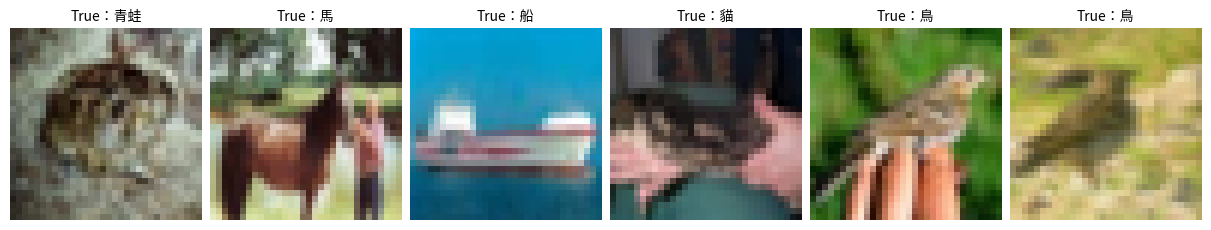

In [ ]:
fig, axes = plt.subplots(1, 6, figsize=(12, 2.6), layout="constrained")
for ax, index in zip(axes, train_indices[:6]):
    ax.imshow(x_train_raw[index])
    ax.set_title(f"True：{class_names[y_train_ids[index]]}", fontproperties=chinese_font)
    ax.axis("off")
plt.show()

In [ ]:
layers = tf.keras.layers
model = tf.keras.Sequential([
    tf.keras.Input(shape=(32, 32, 3), name="image"),
    layers.Conv2D(32, 3, padding="same", activation="relu", name="conv1"),
    layers.MaxPooling2D(2, name="pool1"),
    layers.Conv2D(64, 3, padding="same", activation="relu", name="conv2"),
    layers.MaxPooling2D(2, name="pool2"),
    layers.Conv2D(128, 3, padding="same", activation="relu", name="conv3"),
    layers.MaxPooling2D(2, name="pool3"),
    layers.Flatten(name="flatten"),
    layers.Dense(128, activation="relu", name="dense"),
    layers.Dense(num_classes, activation="softmax", name="class_probabilities"),
], name="cifar10_cnn")
model.summary()

Model: "cifar10_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
batch_size = 128
epochs = 20

batch_tensor = tf.convert_to_tensor(x_train[:batch_size])
print(f"模型輸入：{tuple(batch_tensor.shape)}")
for layer in model.layers:
    input_shape = tuple(batch_tensor.shape)
    batch_tensor = layer(batch_tensor)
    print(f"{layer.name:21s}  {str(input_shape):21s} → {tuple(batch_tensor.shape)}")
print(f"批次 one-hot 標籤：{y_train[:batch_size].shape}")

model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=epochs,
    batch_size=batch_size,
    shuffle=True,
)

模型輸入：(128, 32, 32, 3)
conv1                  (128, 32, 32, 3)      → (128, 32, 32, 32)
pool1                  (128, 32, 32, 32)     → (128, 16, 16, 32)
conv2                  (128, 16, 16, 32)     → (128, 16, 16, 64)
pool2                  (128, 16, 16, 64)     → (128, 8, 8, 64)
conv3                  (128, 8, 8, 64)       → (128, 8, 8, 128)
pool3                  (128, 8, 8, 128)      → (128, 4, 4, 128)
flatten                (128, 4, 4, 128)      → (128, 2048)
dense                  (128, 2048)           → (128, 128)
class_probabilities    (128, 128)            → (128, 10)
批次 one-hot 標籤：(128, 10)
Epoch 1/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 99s 311ms/step - accuracy: 0.4245 - loss: 1.5779 - val_accuracy: 0.5428 - val_loss: 1.2792
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 145s 323ms/step - accuracy: 0.5879 - loss: 1.1614 - val_accuracy: 0.6331 - val_loss: 1.0511
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 101s 322ms/step - accuracy: 0.6557 - loss: 0.9810 - val_accuracy: 0.6767 - val_loss: 0.9473

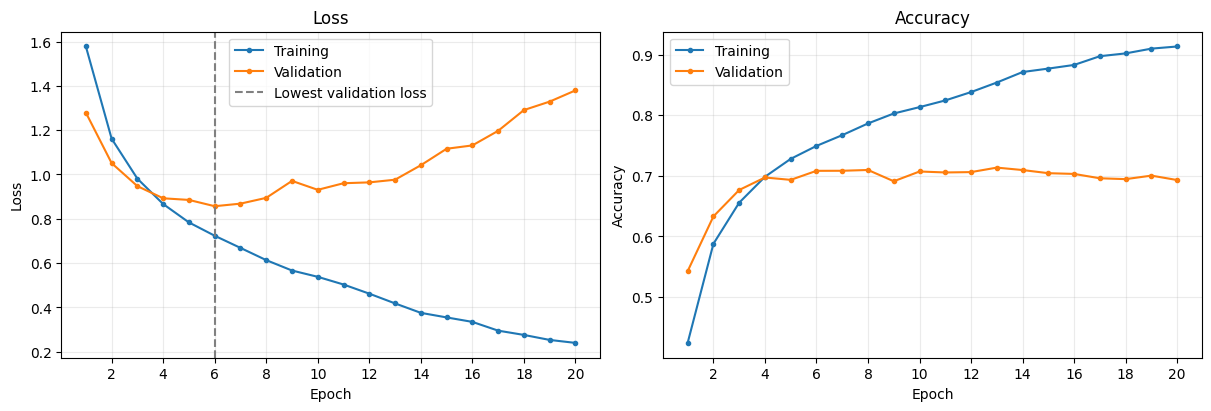

驗證 loss 最低（第 6 輪）｜訓練 loss 0.7234、驗證 loss 0.8567｜訓練 accuracy 74.94%、驗證 accuracy 70.83%
訓練結束（第 20 輪）｜訓練 loss 0.2396、驗證 loss 1.3796｜訓練 accuracy 91.33%、驗證 accuracy 69.31%
訓練 loss 下降、驗證 loss 回升，出現過擬合的跡象。可從折線圖確認差距是否持續擴大。


In [ ]:
metrics = history.history
epoch_numbers = np.arange(1, len(metrics["loss"]) + 1)
best_idx = int(np.argmin(metrics["val_loss"]))
last_idx = len(epoch_numbers) - 1

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, key, title in zip(axes, ["loss", "accuracy"], ["Loss", "Accuracy"]):
    ax.plot(epoch_numbers, metrics[key], marker="o", markersize=3, label="Training")
    ax.plot(epoch_numbers, metrics[f"val_{key}"], marker="o", markersize=3, label="Validation")
    ax.set(
        title=title,
        xlabel="Epoch",
        ylabel=title,
        xticks=np.arange(2, len(epoch_numbers) + 1, 2),
    )
    ax.grid(alpha=0.25)
axes[0].axvline(epoch_numbers[best_idx], color="gray", linestyle="--", label="Lowest validation loss")
for ax in axes:
    ax.legend()
plt.show()

for label, idx in [("驗證 loss 最低", best_idx), ("訓練結束", last_idx)]:
    print(
        f"{label}（第 {epoch_numbers[idx]} 輪）｜"
        f"訓練 loss {metrics['loss'][idx]:.4f}、驗證 loss {metrics['val_loss'][idx]:.4f}｜"
        f"訓練 accuracy {metrics['accuracy'][idx]:.2%}、"
        f"驗證 accuracy {metrics['val_accuracy'][idx]:.2%}"
    )

if (
    best_idx < last_idx
    and metrics["loss"][last_idx] < metrics["loss"][best_idx]
    and metrics["val_loss"][last_idx] > metrics["val_loss"][best_idx]
):
    print("訓練 loss 下降、驗證 loss 回升，出現過擬合的跡象。可從折線圖確認差距是否持續擴大。")
else:
    print("這兩輪的比較未顯示典型的過擬合跡象。請一併查看完整曲線是否有持續分離。")

In [ ]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, batch_size=batch_size, verbose=0)
print(f"測試圖片數量：{len(x_test):,}")
print(f"測試 loss：{test_loss:.4f}")
print(f"測試準確率：{test_accuracy:.2%}")

測試圖片數量：10,000
測試 loss：1.4150
測試準確率：69.36%


79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 74ms/step
已完成 10,000 張測試圖片的預測。


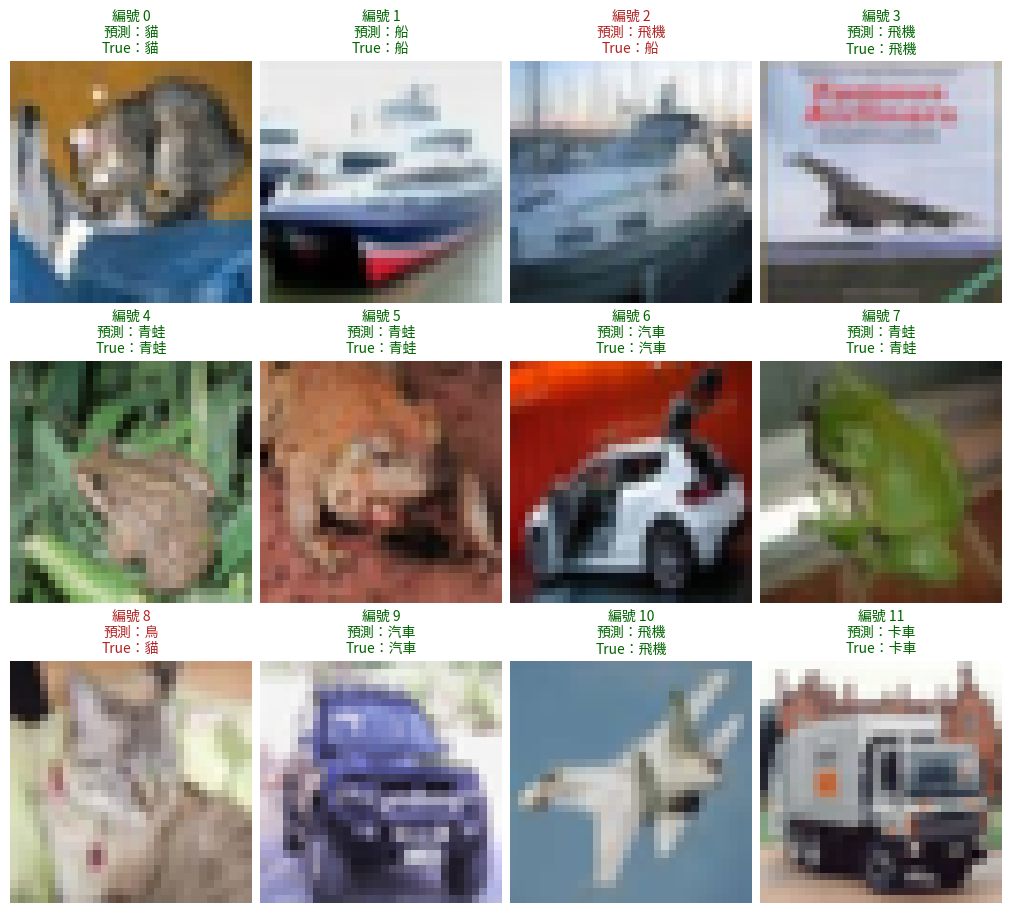

In [ ]:
test_probabilities = model.predict(x_test, batch_size=batch_size, verbose=1)
y_pred_ids = test_probabilities.argmax(axis=1)
assert len(y_pred_ids) == len(y_test_ids) == 10_000
true_names = class_names[y_test_ids]
predicted_names = class_names[y_pred_ids]
print(f"已完成 {len(predicted_names):,} 張測試圖片的預測。")


def show_test_image(ax, index):
    ax.imshow(x_test_raw[index])
    ax.set_title(
        f"編號 {index}\n預測：{predicted_names[index]}\nTrue：{true_names[index]}",
        color="darkgreen" if y_pred_ids[index] == y_test_ids[index] else "firebrick",
        fontproperties=chinese_font,
    )
    ax.axis("off")


fig, axes = plt.subplots(3, 4, figsize=(10, 9), layout="constrained")
for ax, index in zip(axes.flat, range(12)):
    show_test_image(ax, index)
plt.show()

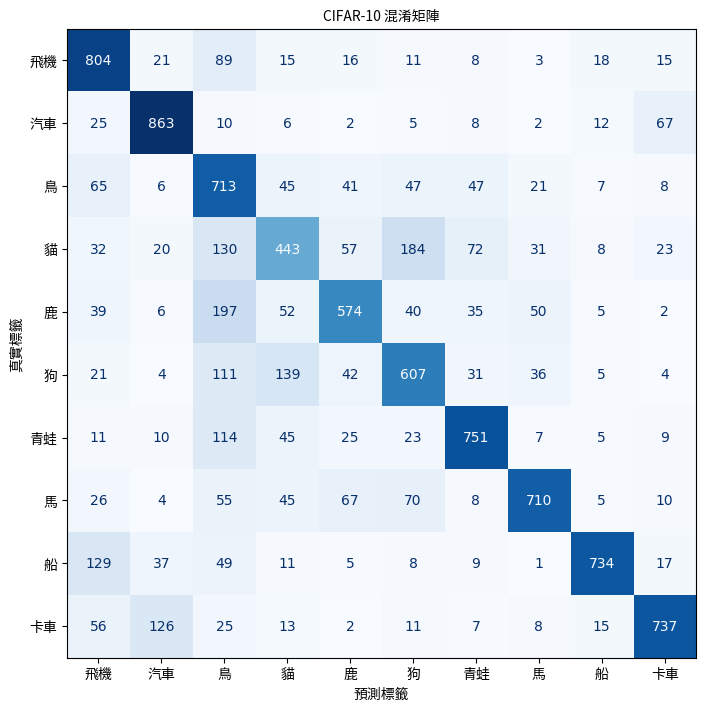

In [ ]:
cm = confusion_matrix(y_test_ids, y_pred_ids, labels=np.arange(num_classes))
assert cm.sum() == len(x_test)

fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False,
)
ax.set_title("CIFAR-10 混淆矩陣", fontproperties=chinese_font)
ax.set_xlabel("預測標籤", fontproperties=chinese_font)
ax.set_ylabel("真實標籤", fontproperties=chinese_font)
for tick in [*ax.get_xticklabels(), *ax.get_yticklabels()]:
    tick.set_fontproperties(chinese_font)
plt.show()

In [ ]:
model_path = Path("cifar10_cnn.keras")
model.save(model_path)
reloaded_model = tf.keras.models.load_model(model_path)

sample = x_test[:1]
np.testing.assert_allclose(
    reloaded_model(sample, training=False).numpy(),
    model(sample, training=False).numpy(),
    rtol=1e-5,
    atol=1e-6,
)
print(f"已儲存並驗證可重新載入：{model_path.resolve()}")

已儲存並驗證可重新載入：/content/cifar10_cnn.keras


In [ ]:
from io import BytesIO
from IPython.display import Image, display
from ipywidgets import interact_manual

def test(測試編號=0):
    fig, ax = plt.subplots(figsize=(3.5, 3.5), layout="constrained")
    show_test_image(ax, 測試編號)

    with BytesIO() as buffer:
        fig.savefig(buffer, format="png")
        display(Image(data=buffer.getvalue()))

    plt.close(fig)

interact_manual(test, 測試編號=(0, 9999));

interactive(children=(IntSlider(value=0, description='測試編號', max=9999), Button(description='Run Interact', sty…